# 04 SAM 实验：视觉大模型的域外边界与 LoRA 救赎

**SAM（Segment Anything Model）**：Meta 2023 发布的视觉基础模型，在 1100 万张自然图像上训练的“可提示分割”大模型，被视为 CV 界的通用底座。

本节回答两个问题：
1. **零样本**：不训练直接用在 SAR 洪水影像上，行不行？
2. **LoRA 微调**：用 1% 参数做高效微调，能救回多少？

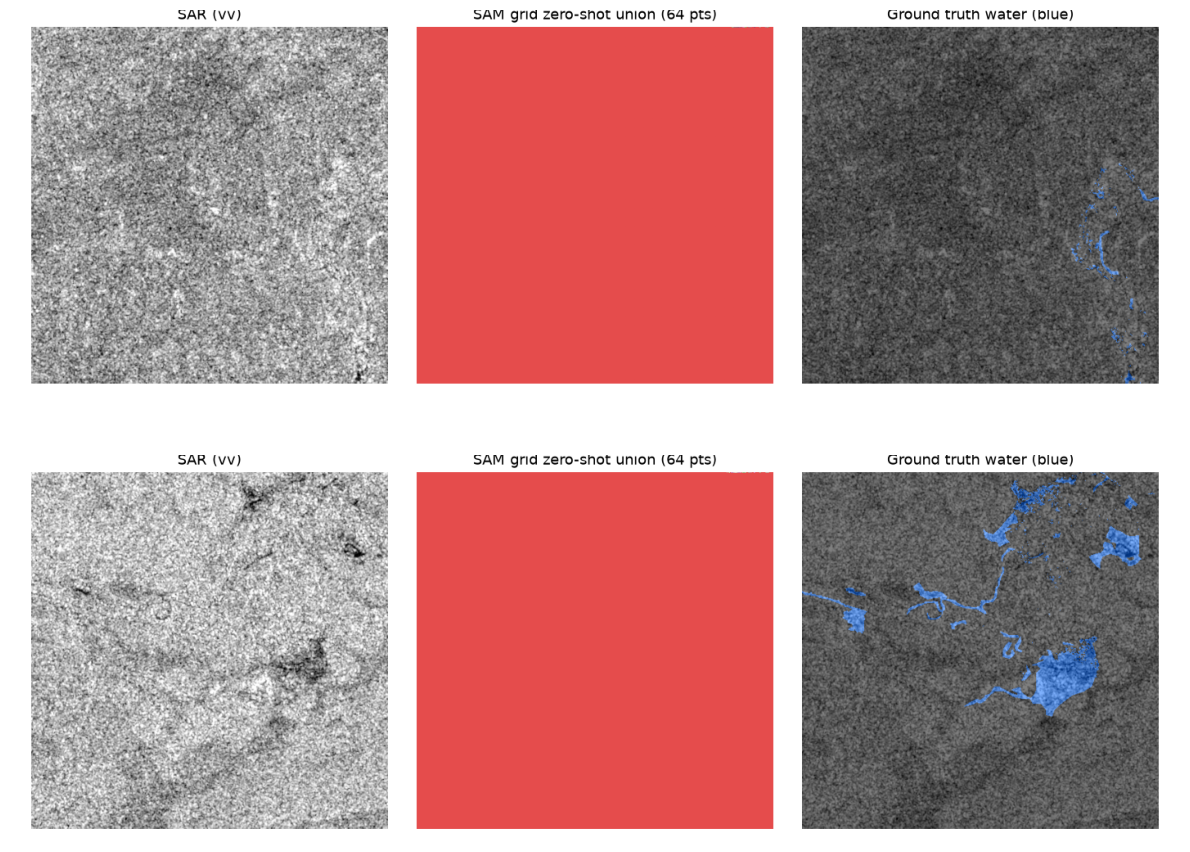

In [1]:
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import pandas as pd

OUT = Path('../outputs')
figs = sorted((OUT / 'figures/sam_grid').glob('*_grid.png'))[:2]
fig, axes = plt.subplots(len(figs), 1, figsize=(12, 4.6 * len(figs)))
for ax, p in zip(axes, figs):
    ax.imshow(mpimg.imread(p)); ax.axis('off')
plt.tight_layout(); plt.show()

### 零样本观察 1：无提示网格扫描（64 个网格点逐个提示）

SAM 对几乎所有点都输出掩码并**覆盖约 100% 像素**，但与真值水体的 IoU 仅 **0.000~0.061**——它一直在“认真分割”，分割的却不是水。SAR 图像的成像机理（相干斑噪、几何畸变）完全在 SAM 的训练分布之外。

In [2]:
z = pd.read_csv(OUT / 'sam_zeroshot_eval.csv')
l = pd.read_csv(OUT / 'sam_lora_v2_eval.csv')
rows = []
for tag, d in [('SAM 零样本', z), ('SAM + LoRA', l)]:
    for s, g in d.groupby('split'):
        rows.append({'模型': tag, 'split': s, 'chips': len(g),
                     'best-IoU': round(g.best.mean(), 4),
                     'mean-IoU': round(g['mean'].mean(), 4),
                     '空掩码率': f"{100 * g.empty_rate.mean():.0f}%"})
pd.DataFrame(rows)

,模型,split,chips,best-IoU,mean-IoU,空掩码率
0,SAM 零样本,bolivia,15,0.1699,0.1699,0%
1,SAM 零样本,test,83,0.1329,0.1328,0%
2,SAM + LoRA,bolivia,15,0.3156,0.2327,0%
3,SAM + LoRA,test,83,0.2668,0.1693,0%


### 零样本观察 2：真值点提示（把水点“喂到嘴边”）

把真值水体像素作为提示点（相当于告诉它“这里就是水”），零样本 best-IoU 也只有 **0.13~0.17**，空掩码率 0%——总有输出，但对象是错的。**结论：94M 参数的视觉大模型在此任务上被 31M 手写 UNet 碾压 5 倍。**

/tmp/ipykernel_114441/3897691481.py:8: UserWarning: Glyph 20004 (\N{CJK UNIFIED IDEOGRAPH-4E24}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_114441/3897691481.py:8: UserWarning: Glyph 27425 (\N{CJK UNIFIED IDEOGRAPH-6B21}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_114441/3897691481.py:8: UserWarning: Glyph 24494 (\N{CJK UNIFIED IDEOGRAPH-5FAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_114441/3897691481.py:8: UserWarning: Glyph 35843 (\N{CJK UNIFIED IDEOGRAPH-8C03}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_114441/3897691481.py:8: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_114441/3897691481.py:8: UserWarning: Glyph 25910 (\N{CJK UNIFIED IDEOGRAPH-6536}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1

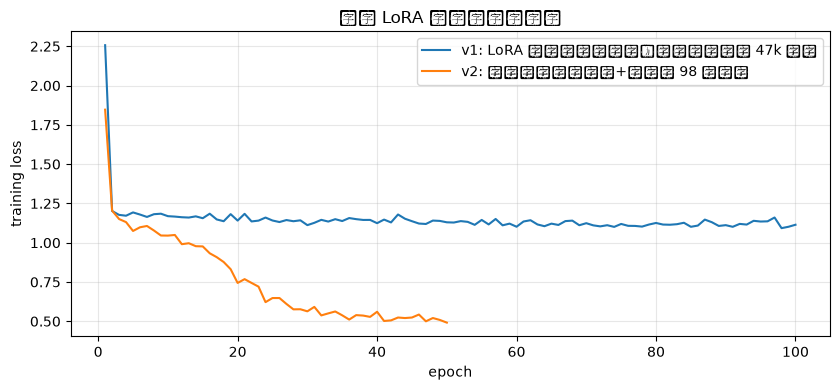

In [3]:
h1 = pd.read_csv(OUT / 'sam_lora_history.csv')
h2 = pd.read_csv(OUT / 'sam_lora_v2_history.csv')
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(h1.epoch, h1.loss, label='v1: LoRA 目标模块名写错，仅命中解码器 47k 参数')
ax.plot(h2.epoch, h2.loss, label='v2: 修正后命中编码器+解码器 98 万参数')
ax.set_xlabel('epoch'); ax.set_ylabel('training loss'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('两次 LoRA 微调的收敛对比')
plt.tight_layout(); plt.show()

### LoRA 微调：一次失败诊断 + 一次修复

- **v1（失败）**：按旧版 API 写的注入目标 `q_proj/v_proj`，在 transformers 5.x 里 SAM 视觉编码器已改用融合的 `attn.qkv/attn.proj`——实际只匹配到解码器里 47,104 个参数（0.05%），评估与零样本完全相同（0.134 ≈ 0.133）
- **v2（修复）**：目标模块全命名覆盖 + 秩 8→16 → 可训练参数 978,944（1.03%），loss 突破 v1 平台
- **结果**：test **0.133 → 0.267（2.0 倍）**，Bolivia 0.170 → 0.316（1.9 倍）——高效微调显著起效，但**与专用模型的量级差距仍在**（UNet 0.664）

/home/ctgu53/work/cv-course-design/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 4501.36it/s]

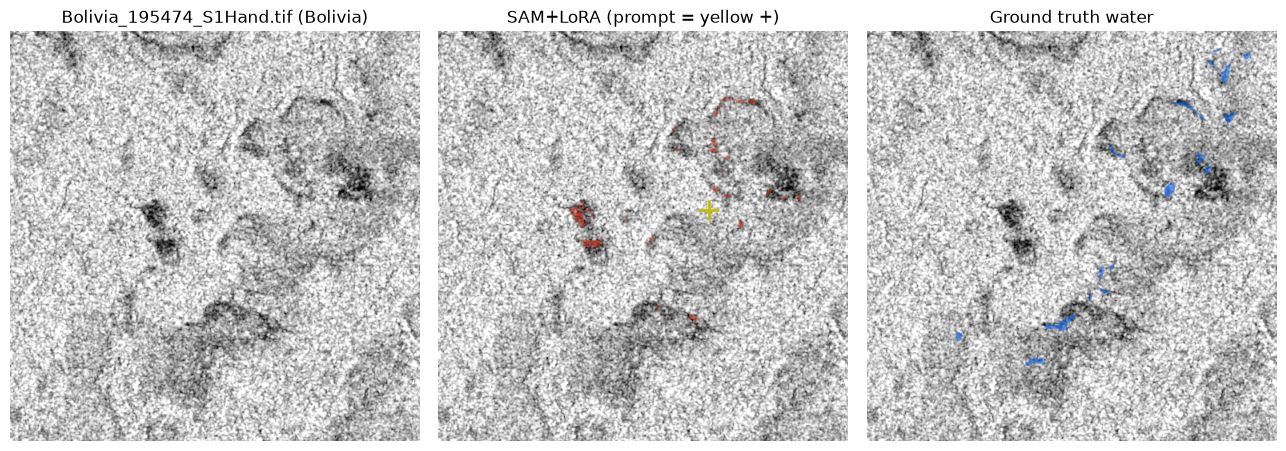

In [4]:
import os
os.environ['HF_HUB_OFFLINE'] = '1'
import sys
sys.path.insert(0, '..')
import numpy as np
import torch
from peft import PeftModel
from transformers import SamModel, SamProcessor
from src.dataset import Sen1FloodsDataset

base = SamModel.from_pretrained('facebook/sam-vit-base')
model = PeftModel.from_pretrained(base, str(OUT / 'checkpoints/sam_lora_v2_adapter')).to('cuda').eval()
proc = SamProcessor.from_pretrained('facebook/sam-vit-base')
ds = Sen1FloodsDataset('bolivia', augment=False)
img, water, valid, name = ds[2]
v = valid.numpy()
ys, xs = np.where((water[0] > 0).numpy() & v)
cx, cy = int(xs.mean()), int(ys.mean())
rgb = torch.stack([img[0], img[1], img[0]], dim=-1).numpy()
inputs = proc(rgb, input_points=[[[cx, cy]]], return_tensors='pt').to('cuda')
with torch.no_grad():
    out = model(**inputs, multimask_output=False)
pm = out.pred_masks.reshape(-1, 1, out.pred_masks.shape[-2], out.pred_masks.shape[-1])
m = torch.nn.functional.interpolate(pm.float(), size=(512, 512), mode='bilinear', align_corners=False)
m = (m.sigmoid()[0, 0].cpu().numpy() > 0.5) * v
gt = (water[0].numpy() > 0.5) * v

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
axes[0].imshow(rgb[..., 0], cmap='gray'); axes[0].set_title(f'{name} (Bolivia)')
axes[1].imshow(rgb[..., 0], cmap='gray')
ov = np.zeros((*v.shape, 4)); ov[m > 0] = [1, 0.3, 0.2, 0.55]
axes[1].imshow(ov); axes[1].plot(cx, cy, 'y+', ms=14, mew=2)
axes[1].set_title('SAM+LoRA (prompt = yellow +)')
axes[2].imshow(rgb[..., 0], cmap='gray')
ov = np.zeros((*v.shape, 4)); ov[gt > 0] = [0, 0.4, 1, 0.55]
axes[2].imshow(ov); axes[2].set_title('Ground truth water')
for ax in axes:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 三代四行总表（全项目核心结果）

| 模型 | test microIoU | Bolivia（OOD） | 备注 |
| --- | --- | --- | --- |
| UNet 手写（31M，全参训练） | 0.664 | **0.696** | OOD 最稳 |
| SegFormer-B2（27M，预训练微调） | **0.681** | 0.571 | 分布内最强 |
| SAM 零样本（94M，冻结） | 0.133 | 0.170 | 域外近乎失明 |
| SAM + LoRA（微调 98 万参数） | 0.267 | 0.316 | 翻倍，量级差距仍在 |

## 讨论：大模型不是即插即用

1. **零样本的边界**：SAM 的“通用”建立在训练分布内；SAR 遥感对其是彻底的域外，零样本不可用（IoU 0.13 vs 专用模型 0.66）
2. **高效微调的价值与限度**：98 万参数（1%）换来 2 倍提升，验证 LoRA 类方法在跨域适配上的有效性；但受限于 SAM 的提示式架构与语义分割任务的错配，未能接近专用模型
3. **另一处细节**：微调后 best-IoU（0.267）远高于 mean-IoU（0.169）——提示点落在水体哪个位置对结果影响巨大，这是交互式模型的固有特性，全自动场景需要提示点策略配合
4. **对水利 AI 的启示**：大模型时代，**领域数据集与域适配方法**（本报告作者的研究方向）依然不可替代——这恰是“专用小模型仍占一席之地”与“大模型需要微调”两条证据线的交汇点